In [1]:
%pip install -q numpy scipy matplotlib qiskit==2.3.1 qiskit-aer==0.17.2


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
from pathlib import Path
# make `evqaoa` and `experiments` importable whether the notebook runs from notebooks/ or the project root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'evqaoa').is_dir())
sys.path.insert(0, str(ROOT))
OUT = ROOT / 'results' / '04_optimizers'
OUT.mkdir(parents=True, exist_ok=True)

# 04 - Which optimizer? And does CVaR help?

## Motivation
QAOA is a *hybrid* algorithm. A quantum circuit with angles `(betas, gammas)` produces a distribution over schedules, and a **classical optimizer** tunes those angles to lower the expected cost of our overnight EV-charging objective. The hackathon starter notebook runs one optimizer (COBYLA) for a short budget and moves on. Here we ask what the choice of optimizer is worth:

1. **Which optimizer** reaches a good schedule distribution with the fewest circuit evaluations? Each evaluation costs real quantum-computer time.
2. **Which optimizers survive shot noise?** On hardware you never see the exact energy, only an average over a finite number of shots.
3. **Does CVaR help?** Instead of the average over all sampled shots, CVaR-alpha (Barkoutsas et al. 2020) averages only the best `alpha` fraction of shots. We want to *find* the best schedule rather than have a good average, so this might be a better target.

## Workflow
Problem: the reference depot (3 vehicles x 4 slots = 12 qubits, 144 valid schedules, 4 of them tied at the optimum), weights `(0.5, 0.3, 0.2)`, XY mixer with a Dicke start (so every sampled schedule is valid), depths p = 1 and 2.
1. Build the circuit and tabulate the energy of all 4096 bitstrings, so any set of angles is evaluated from statevector probabilities.
2. **Experiment 1:** six optimizer settings, exact energy, identical random starting angles for 8 seeds, counting evaluations. These are COBYLA, Nelder-Mead, Powell, L-BFGS-B, our own SPSA, and "low-budget COBYLA" (capped at 30 evaluations, like the short quick run in the starter notebook).
3. **Experiment 2:** the same optimizers (except the low-budget one) when the energy is estimated from 256 or 1024 shots.
4. **Experiment 3:** CVaR with alpha in {0.1, 0.25, 0.5, 1.0} under 1024 shots.

Final angles are always scored with the **exact** statevector, so noise only affects the optimisation, not the judgement.

**Metrics.** *Approximation ratio* = (worst - mean energy of the output) / (worst - best), over valid schedules: 1 means always optimal, and the random-valid-schedule value is printed below as a reference line. *P(optimal)* = probability that the output is one of the 4 optimal schedules.

In [3]:
import json, time
import numpy as np
import matplotlib.pyplot as plt
from qiskit.quantum_info import Statevector
from evqaoa import (DEPOT, charging_model, to_ising, qaoa_circuit, exact_baselines,
                    energy_function, score_distribution, output_distribution)
from experiments.optimizers import (run_optimizer, all_bitstring_energies, shot_objective,
                                    score_probs, fast_probabilities)

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
T0 = time.time()
model = charging_model(DEPOT, weights=(0.5, 0.3, 0.2))
H = to_ising(model)
base = exact_baselines(DEPOT, model)
ENERGY = all_bitstring_energies(model)
print(f'{DEPOT.n_qubits} qubits, {base.n_valid} valid schedules, {base.n_optimal} tied at the optimum')
print(f'best {base.best:.4f} | random valid (mean) {base.mean:.4f} | worst {base.worst:.4f}')
RANDOM_RATIO = (base.worst - base.mean) / (base.worst - base.best)
print(f'approximation ratio of a random valid schedule: {RANDOM_RATIO:.3f}')

12 qubits, 144 valid schedules, 4 tied at the optimum
best 0.5695 | random valid (mean) 0.6894 | worst 0.9250
approximation ratio of a random valid schedule: 0.663


In [4]:
CIRCUITS = {p: qaoa_circuit(DEPOT, H, p, mixer='xy', start='dicke') for p in (1, 2)}

FAST = {p: fast_probabilities(c) for p, c in CIRCUITS.items()}   # start state is prepared only once

def probs_of(p):
    return FAST[p]

# sanity checks: our fast energy table agrees with the core library
th = np.random.default_rng(0).uniform(0, np.pi, 4)
assert np.allclose(probs_of(2)(th), Statevector(CIRCUITS[2].assign_parameters(th)).probabilities())
assert abs(probs_of(2)(th) @ ENERGY - energy_function(CIRCUITS[2], H)(th)) < 1e-9
dist = output_distribution(CIRCUITS[2], th)
fast = score_probs(probs_of(2)(th), DEPOT, model, base)
slow = score_distribution(dist, DEPOT, model, base)
assert abs(fast['p_optimal'] - slow['p_optimal']) < 1e-9 and abs(fast['approx_ratio'] - slow['approx_ratio']) < 1e-9

def final_metrics(p, theta):
    """Score angles with the exact statevector (no shot noise)."""
    return score_probs(probs_of(p)(theta), DEPOT, model, base)

def exact_objective(p):
    return lambda theta: float(probs_of(p)(theta) @ ENERGY)

def start_point(p, seed):
    return np.random.default_rng(seed).uniform(0, np.pi, 2 * p)   # [betas..., gammas...]

CHECK_STRIDE = 10
def convergence_curve(p, res, budget):
    """Exact energy of the best-so-far (by observed value) point, checked every CHECK_STRIDE evaluations."""
    vals, pts = np.array(res['values']), res['points']
    out = []
    for n in range(CHECK_STRIDE, budget + 1, CHECK_STRIDE):
        m = min(n, len(vals))
        out.append(float(probs_of(p)(pts[int(np.argmin(vals[:m]))]) @ ENERGY))
    return out

SUCCESS_RATIO = 0.80   # a run "succeeds" if its final approximation ratio is at least this
def summarise(rows):
    keys = ['approx_ratio', 'p_optimal', 'nfev']
    s = {k: (float(np.mean([r[k] for r in rows])), float(np.std([r[k] for r in rows]))) for k in keys}
    s['success_rate'] = float(np.mean([r['approx_ratio'] >= SUCCESS_RATIO for r in rows]))
    return s

METHODS = ['COBYLA', 'Nelder-Mead', 'Powell', 'L-BFGS-B', 'SPSA']

## Experiment 1 - optimizer comparison with the exact energy
Every optimizer gets the **same random starting angles** for each of 8 seeds and a budget of 200 circuit evaluations. "COBYLA (low budget)" is COBYLA stopped after 30 evaluations, a short quick run like the one in the starter notebook. SPSA is our own 25-line implementation (two evaluations per step regardless of the number of parameters, after Spall). L-BFGS-B has to estimate its gradient by finite differences, so every gradient costs `2p + 1` evaluations.

In [5]:
BUDGET, SEEDS_EXACT = 200, list(range(8))
LOW = 'COBYLA (low budget)'
CONFIGS = [(m, BUDGET, m) for m in METHODS] + [('COBYLA', 30, LOW)]

exp1, exp1_curves = {}, {}
for p in (1, 2):
    f = exact_objective(p)
    for m, b, name in CONFIGS:
        rows, curves = [], []
        for s in SEEDS_EXACT:
            res = run_optimizer(f, start_point(p, s), m, b, seed=s)
            rows.append({**final_metrics(p, res['x']), 'nfev': res['nfev']})
            curves.append(convergence_curve(p, res, BUDGET))
        exp1[(p, name)] = summarise(rows)
        exp1_curves[(p, name)] = np.array(curves)
print(f'Experiment 1 done  ({time.time() - T0:.0f}s elapsed)')
print(f"{'p':>2} {'optimizer':<21}{'approx ratio':>14}{'P(opt)':>9}{'evals':>7}{'success':>9}")
for (p, name), s in exp1.items():
    print(f"{p:>2} {name:<21}{s['approx_ratio'][0]:>8.3f}+-{s['approx_ratio'][1]:.3f}{s['p_optimal'][0]:>9.3f}"
          f"{s['nfev'][0]:>7.0f}{s['success_rate']:>9.0%}")

Experiment 1 done  (29s elapsed)
 p optimizer              approx ratio   P(opt)  evals  success
 1 COBYLA                  0.691+-0.028    0.030    118       0%
 1 Nelder-Mead             0.784+-0.039    0.069    162       0%
 1 Powell                  0.759+-0.057    0.064     86       0%
 1 L-BFGS-B                0.714+-0.066    0.044     31       0%
 1 SPSA                    0.667+-0.007    0.028    199       0%
 1 COBYLA (low budget)     0.677+-0.016    0.028     30       0%
 2 COBYLA                  0.792+-0.018    0.094    200      25%
 2 Nelder-Mead             0.813+-0.013    0.078    200      88%
 2 Powell                  0.816+-0.014    0.079    178     100%
 2 L-BFGS-B                0.827+-0.001    0.122    188     100%
 2 SPSA                    0.733+-0.053    0.066    199       0%
 2 COBYLA (low budget)     0.779+-0.019    0.088     30      12%


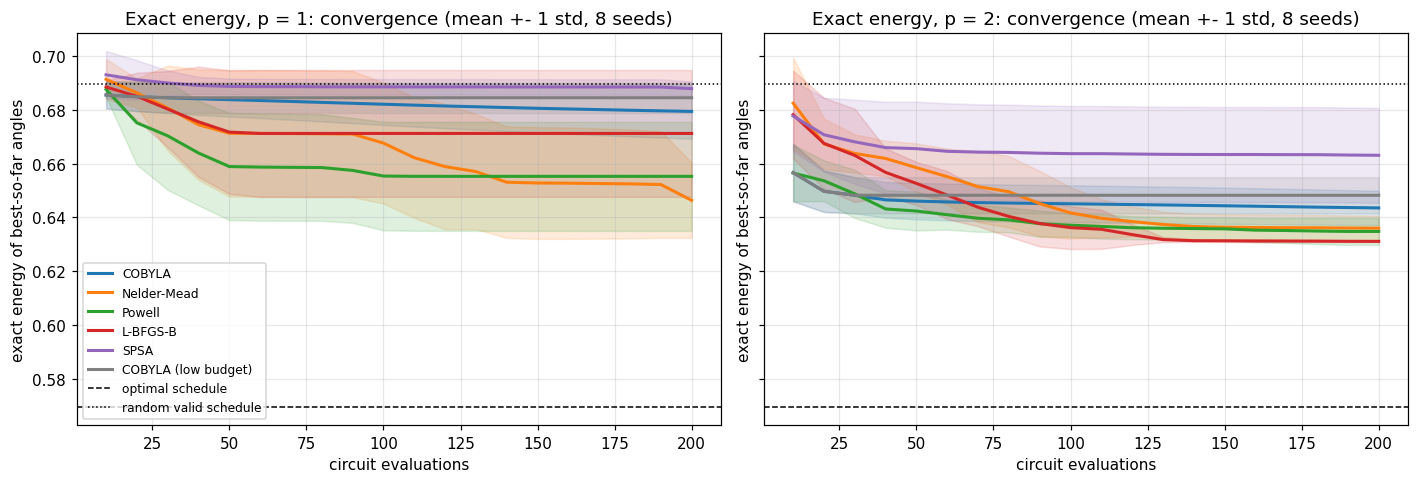

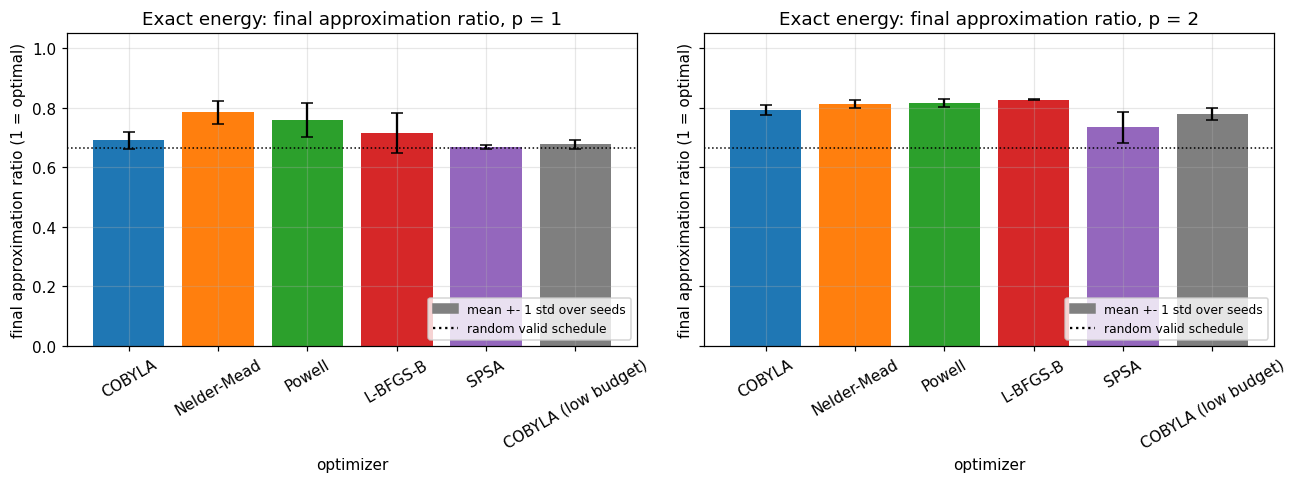

In [6]:
COLORS = {'COBYLA': '#1f77b4', 'Nelder-Mead': '#ff7f0e', 'Powell': '#2ca02c', 'L-BFGS-B': '#d62728',
          'SPSA': '#9467bd', LOW: '#7f7f7f'}
xs = np.arange(CHECK_STRIDE, BUDGET + 1, CHECK_STRIDE)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, p in zip(axes, (1, 2)):
    for (pp, name), c in exp1_curves.items():
        if pp != p: continue
        mu, sd = c.mean(0), c.std(0)
        ax.plot(xs, mu, color=COLORS[name], label=name, lw=2)
        ax.fill_between(xs, mu - sd, mu + sd, color=COLORS[name], alpha=0.15)
    ax.axhline(base.best, color='k', ls='--', lw=1, label='optimal schedule')
    ax.axhline(base.mean, color='k', ls=':', lw=1, label='random valid schedule')
    ax.set_title(f'Exact energy, p = {p}: convergence (mean +- 1 std, 8 seeds)')
    ax.set_xlabel('circuit evaluations'); ax.set_ylabel('exact energy of best-so-far angles')
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / 'convergence_exact.png'); plt.show()

names1 = METHODS + [LOW]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, p in zip(axes, (1, 2)):
    mu = [exp1[(p, n)]['approx_ratio'][0] for n in names1]
    sd = [exp1[(p, n)]['approx_ratio'][1] for n in names1]
    ax.bar(names1, mu, yerr=sd, capsize=4, color=[COLORS[n] for n in names1])
    ax.axhline(RANDOM_RATIO, color='k', ls=':', lw=1)
    ax.set_title(f'Exact energy: final approximation ratio, p = {p}')
    ax.set_ylabel('final approximation ratio (1 = optimal)'); ax.set_xlabel('optimizer')
    ax.tick_params(axis='x', rotation=30); ax.set_ylim(0, 1.05)
    ax.legend([plt.Rectangle((0, 0), 1, 1, color='gray'), plt.Line2D([], [], color='k', ls=':')],
              ['mean +- 1 std over seeds', 'random valid schedule'], fontsize=8, loc='lower right')
plt.tight_layout(); plt.savefig(OUT / 'approx_ratio_exact.png'); plt.show()

## Experiment 2 - the same optimizers with shot noise
Now the objective is the **mean of `shots` sampled energies** (multinomial sampling from the statevector probabilities). Every run has its own fixed random stream, so results are reproducible. The final angles are still scored exactly. Budget 200 evaluations, 6 seeds, p = 1 and 2.

In [7]:
SEEDS_NOISY, BUDGET_N = list(range(6)), 200
xs_n = np.arange(CHECK_STRIDE, BUDGET_N + 1, CHECK_STRIDE)
exp2, exp2_curves = {}, {}
for shots in (256, 1024):
    for p in (1, 2):
        for m in METHODS:
            rows, curves = [], []
            for s in SEEDS_NOISY:
                f = shot_objective(probs_of(p), ENERGY, shots, np.random.default_rng(1000 + s))
                res = run_optimizer(f, start_point(p, s), m, BUDGET_N, seed=s)
                rows.append({**final_metrics(p, res['x']), 'nfev': res['nfev']})
                curves.append(convergence_curve(p, res, BUDGET_N))
            exp2[(shots, p, m)] = summarise(rows)
            exp2_curves[(shots, p, m)] = np.array(curves)
print(f'Experiment 2 done  ({time.time() - T0:.0f}s elapsed)')
print(f"{'shots':>5} {'p':>2} {'optimizer':<13}{'approx ratio':>14}{'P(opt)':>9}{'evals':>7}{'success':>9}")
for (shots, p, m), s in exp2.items():
    print(f"{shots:>5} {p:>2} {m:<13}{s['approx_ratio'][0]:>8.3f}+-{s['approx_ratio'][1]:.3f}{s['p_optimal'][0]:>9.3f}"
          f"{s['nfev'][0]:>7.0f}{s['success_rate']:>9.0%}")

Experiment 2 done  (67s elapsed)
shots  p optimizer      approx ratio   P(opt)  evals  success
  256  1 COBYLA          0.670+-0.014    0.022     28       0%
  256  1 Nelder-Mead     0.638+-0.037    0.018    200       0%
  256  1 Powell          0.738+-0.057    0.054    119       0%
  256  1 L-BFGS-B        0.625+-0.037    0.014     98       0%
  256  1 SPSA            0.668+-0.008    0.028    199       0%
  256  2 COBYLA          0.762+-0.027    0.078     47      17%
  256  2 Nelder-Mead     0.678+-0.055    0.031    200       0%
  256  2 Powell          0.790+-0.023    0.072    200      33%
  256  2 L-BFGS-B        0.644+-0.050    0.018    122       0%
  256  2 SPSA            0.749+-0.033    0.073    199       0%
 1024  1 COBYLA          0.668+-0.009    0.028     28       0%
 1024  1 Nelder-Mead     0.644+-0.040    0.021    200       0%
 1024  1 Powell          0.750+-0.064    0.056    125       0%
 1024  1 L-BFGS-B        0.625+-0.037    0.014     74       0%
 1024  1 SPSA          

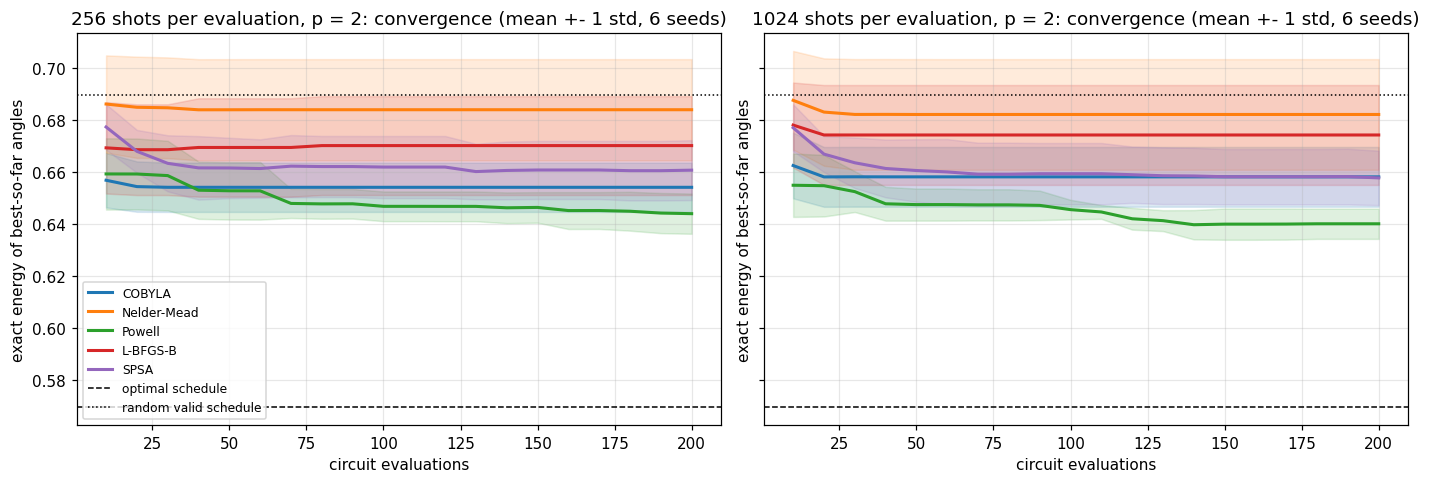

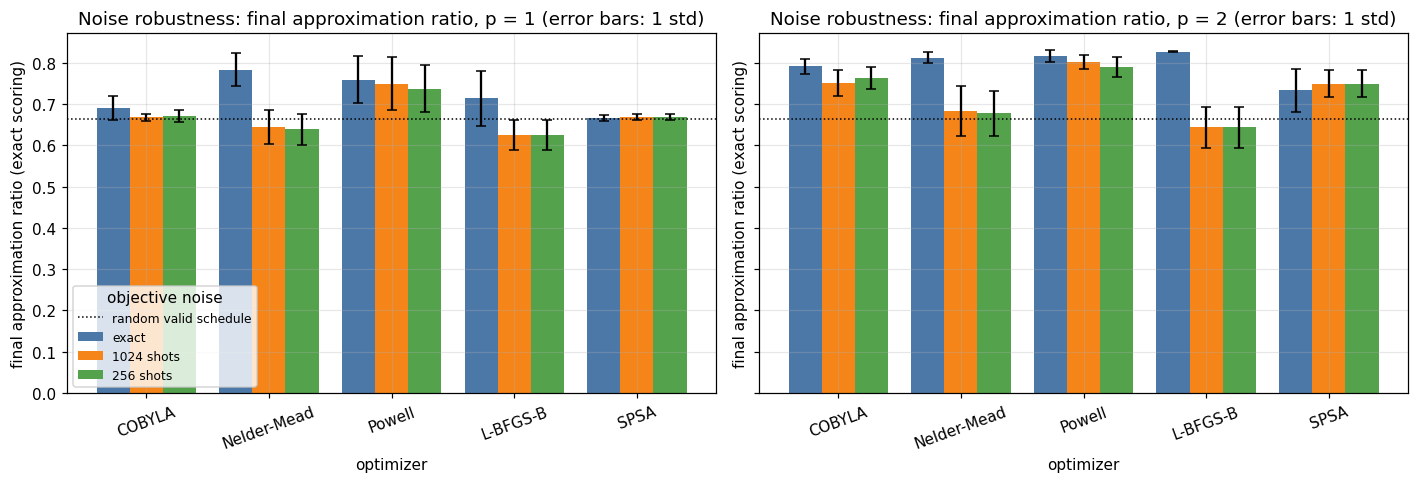

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, shots in zip(axes, (256, 1024)):
    for m in METHODS:
        c = exp2_curves[(shots, 2, m)]
        ax.plot(xs_n, c.mean(0), color=COLORS[m], label=m, lw=2)
        ax.fill_between(xs_n, c.mean(0) - c.std(0), c.mean(0) + c.std(0), color=COLORS[m], alpha=0.15)
    ax.axhline(base.best, color='k', ls='--', lw=1, label='optimal schedule')
    ax.axhline(base.mean, color='k', ls=':', lw=1, label='random valid schedule')
    ax.set_title(f'{shots} shots per evaluation, p = 2: convergence (mean +- 1 std, 6 seeds)')
    ax.set_xlabel('circuit evaluations'); ax.set_ylabel('exact energy of best-so-far angles')
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / 'convergence_noisy.png'); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
width = 0.27
for ax, p in zip(axes, (1, 2)):
    for j, (lab, get) in enumerate([('exact', lambda m: exp1[(p, m)]),
                                    ('1024 shots', lambda m: exp2[(1024, p, m)]),
                                    ('256 shots', lambda m: exp2[(256, p, m)])]):
        mu = [get(m)['approx_ratio'][0] for m in METHODS]; sd = [get(m)['approx_ratio'][1] for m in METHODS]
        ax.bar(np.arange(5) + (j - 1) * width, mu, width, yerr=sd, capsize=3, label=lab,
               color=['#4c78a8', '#f58518', '#54a24b'][j])
    ax.axhline(RANDOM_RATIO, color='k', ls=':', lw=1, label='random valid schedule')
    ax.set_xticks(range(5)); ax.set_xticklabels(METHODS, rotation=20)
    ax.set_title(f'Noise robustness: final approximation ratio, p = {p} (error bars: 1 std)')
    ax.set_xlabel('optimizer'); ax.set_ylabel('final approximation ratio (exact scoring)')
axes[0].legend(title='objective noise', fontsize=8)
plt.tight_layout(); plt.savefig(OUT / 'approx_ratio_noisy.png'); plt.show()

## Experiment 3 - CVaR-alpha objective under shots
With `shots` sampled schedules, the objective is the **mean of the lowest `alpha` fraction of their energies**. `alpha = 1` is the ordinary expectation; a small alpha rewards only the luckiest samples. The headline metric is P(optimal schedule) evaluated **exactly** at the final angles. We use COBYLA and SPSA at 1024 shots, budget 150, 6 seeds.

In [9]:
ALPHAS, BUDGET_C, SHOTS_C = [0.1, 0.25, 0.5, 1.0], 150, 1024
exp3 = {}
for p in (1, 2):
    for m in ('COBYLA', 'SPSA'):
        for a in ALPHAS:
            rows = []
            for s in SEEDS_NOISY:
                f = shot_objective(probs_of(p), ENERGY, SHOTS_C, np.random.default_rng(2000 + s), alpha=a)
                res = run_optimizer(f, start_point(p, s), m, BUDGET_C, seed=s)
                rows.append({**final_metrics(p, res['x']), 'nfev': res['nfev']})
            exp3[(p, m, a)] = summarise(rows)
print(f'Experiment 3 done  ({time.time() - T0:.0f}s elapsed)')
print(f"{'p':>2} {'opt':<8}{'alpha':>6}{'P(opt)':>16}{'approx ratio':>16}")
for (p, m, a), s in exp3.items():
    print(f"{p:>2} {m:<8}{a:>6}{s['p_optimal'][0]:>10.3f}+-{s['p_optimal'][1]:.3f}"
          f"{s['approx_ratio'][0]:>10.3f}+-{s['approx_ratio'][1]:.3f}")

Experiment 3 done  (85s elapsed)
 p opt      alpha          P(opt)    approx ratio
 1 COBYLA     0.1     0.027+-0.002     0.667+-0.010
 1 COBYLA    0.25     0.027+-0.002     0.671+-0.012
 1 COBYLA     0.5     0.026+-0.004     0.669+-0.007
 1 COBYLA     1.0     0.028+-0.001     0.671+-0.009
 1 SPSA       0.1     0.028+-0.001     0.667+-0.006
 1 SPSA      0.25     0.028+-0.001     0.667+-0.007
 1 SPSA       0.5     0.028+-0.000     0.668+-0.007
 1 SPSA       1.0     0.028+-0.000     0.668+-0.008
 2 COBYLA     0.1     0.087+-0.011     0.764+-0.026
 2 COBYLA    0.25     0.088+-0.012     0.768+-0.024
 2 COBYLA     0.5     0.088+-0.014     0.768+-0.027
 2 COBYLA     1.0     0.092+-0.010     0.776+-0.023
 2 SPSA       0.1     0.063+-0.019     0.726+-0.035
 2 SPSA      0.25     0.072+-0.023     0.740+-0.038
 2 SPSA       0.5     0.073+-0.023     0.745+-0.035
 2 SPSA       1.0     0.072+-0.026     0.749+-0.033


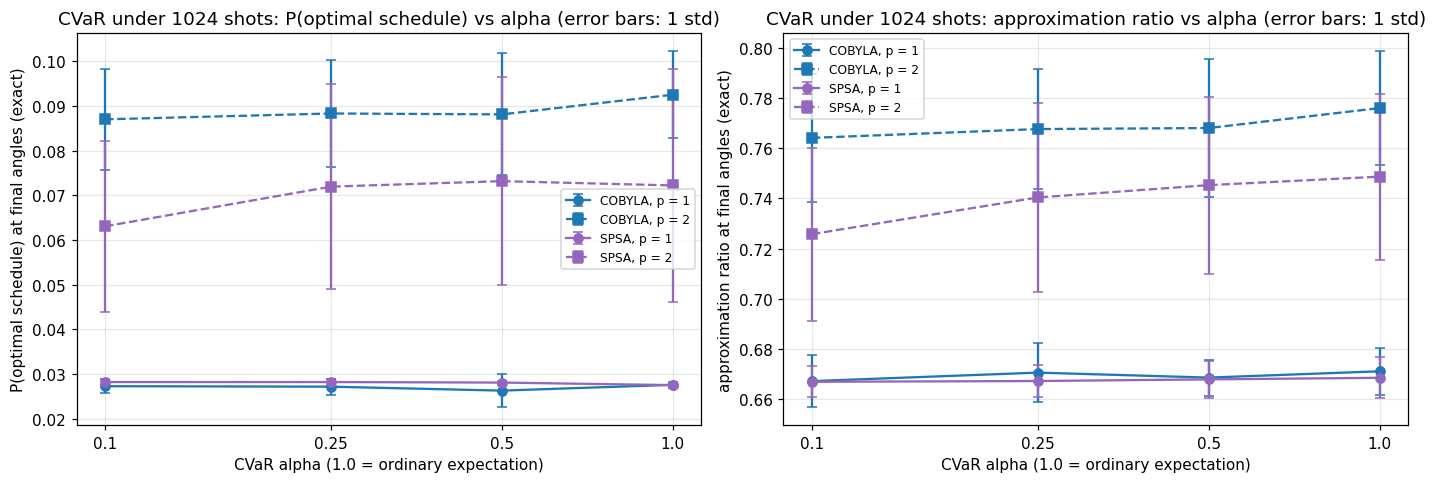

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
styles = {('COBYLA', 1): ('-o', '#1f77b4'), ('COBYLA', 2): ('--s', '#1f77b4'),
          ('SPSA', 1): ('-o', '#9467bd'), ('SPSA', 2): ('--s', '#9467bd')}
for ax, (metric, title) in zip(axes, [('p_optimal', 'P(optimal schedule)'), ('approx_ratio', 'approximation ratio')]):
    for (m, p), (st, col) in styles.items():
        mu = [exp3[(p, m, a)][metric][0] for a in ALPHAS]; sd = [exp3[(p, m, a)][metric][1] for a in ALPHAS]
        ax.errorbar(ALPHAS, mu, yerr=sd, fmt=st, color=col, capsize=3, label=f'{m}, p = {p}')
    ax.set_xscale('log'); ax.set_xticks(ALPHAS); ax.set_xticklabels(ALPHAS); ax.minorticks_off()
    ax.set_title(f'CVaR under {SHOTS_C} shots: {title} vs alpha (error bars: 1 std)')
    ax.set_xlabel('CVaR alpha (1.0 = ordinary expectation)')
    ax.set_ylabel(title + ' at final angles (exact)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / 'cvar_vs_alpha.png'); plt.show()

In [11]:
def enc(d): return {' | '.join(map(str, k)): v for k, v in d.items()}
RUNTIME = time.time() - T0
json.dump({'config': {'success_ratio': SUCCESS_RATIO, 'budget_exact': BUDGET, 'budget_noisy': BUDGET_N,
                      'budget_cvar': BUDGET_C, 'seeds_exact': len(SEEDS_EXACT), 'seeds_noisy': len(SEEDS_NOISY),
                      'E_best': base.best, 'E_mean': base.mean, 'E_worst': base.worst,
                      'n_valid': base.n_valid, 'n_optimal': base.n_optimal,
                      'random_valid_ratio': RANDOM_RATIO, 'runtime_s': RUNTIME},
           'exp1_exact': enc(exp1), 'exp2_noisy': enc(exp2), 'exp3_cvar': enc(exp3)},
          open(OUT / 'results.json', 'w'), indent=2)
print(f'saved results.json and PNGs to {OUT.relative_to(ROOT)}; total runtime {RUNTIME:.0f}s')

saved results.json and PNGs to results/04_optimizers; total runtime 85s


## Findings & limitations

Numbers come from the tables printed above (also in `results/04_optimizers/results.json`). Approximation ratio 1 means the optimal schedule; a random valid schedule scores **0.663**. P(optimal) is the probability of any of the 4 tied optimal schedules (a random valid schedule gives 4/144 = 0.028). "Success" means a final ratio of at least 0.80.

**Exact energy (8 seeds, budget 200)**
- p = 1 is a hard ceiling: no optimizer reaches 0.80 and the best mean ratio is Nelder-Mead 0.784 (P(opt) 0.069), then Powell 0.759 (0.064, in 86 evaluations), L-BFGS-B 0.714 (0.044, only 31 evaluations, stops early), COBYLA 0.691 (0.030). Our SPSA (0.667) and low-budget COBYLA (0.677, 30 evaluations) barely move off the random-schedule level of 0.663.
- p = 2 helps every method that converges: L-BFGS-B 0.827 (P(opt) 0.122, 100% success, 188 evaluations, almost no spread across seeds), Powell 0.816 (0.079, 100%), Nelder-Mead 0.813 (0.078, 88%), COBYLA 0.792 (0.094, 25%), low-budget COBYLA 0.779 (0.088, 12%), SPSA 0.733 (0.066, 0%).
- The p = 1 to p = 2 gain (about +0.04 to +0.12 ratio) is larger than the gaps between the good optimizers. With the budget cut to 30 evaluations COBYLA loses only 0.013 ratio at p = 2 (0.792 to 0.779).

**Shot noise (6 seeds, budget 200)**
- Powell is the most robust at p = 2: 0.790 (256 shots) and 0.802 (1024 shots), against 0.816 exact. At 1024 shots 50% of its runs reach 0.80.
- COBYLA at p = 2 gets 0.762 / 0.751 (256 / 1024 shots), but it stops after only 47 evaluations on average, so it is cheap and sits in the middle of the field.
- SPSA is essentially noise-proof (p = 2: 0.749 at both shot counts, versus 0.733 exact) but converges slowly.
- L-BFGS-B, the best exact optimizer, collapses to 0.644 at p = 2 (0.625 at p = 1), because finite-difference gradients are swamped by sampling noise. Nelder-Mead falls from 0.813 to 0.678 / 0.683 and uses the full budget.
- At p = 1 under shot noise only Powell stays above the random level (0.738 / 0.750); the rest sit at 0.625 to 0.670.

**CVaR (1024 shots, budget 150, 6 seeds)**
- CVaR did **not** help here. COBYLA at p = 2: P(opt) 0.087 (alpha 0.1), 0.088 (0.25), 0.088 (0.5), 0.092 (1.0, ordinary mean); the approximation ratio shows the same ordering (0.764, 0.768, 0.768, 0.776). SPSA at p = 2: 0.063, 0.072, 0.073, 0.072. The differences are within one standard deviation of the seeds, except that alpha = 0.1 looks slightly worse for SPSA.
- At p = 1 the curves are flat (P(opt) 0.026 to 0.028, which equals random), so the optimizer, not the objective, is the bottleneck there.
- Likely reason: the XY mixer with a Dicke start only produces valid schedules, so there are no invalid samples for CVaR to ignore, and a small alpha keeps just a handful of samples, which makes the objective noisier. CVaR may matter more with the X mixer or penalty terms, which this study did not test.

**Recommendation.** With exact or very low-noise evaluation use L-BFGS-B at p = 2 (best ratio and P(opt), tiny seed spread), or Powell if you want one method that also holds up under shot noise. On shot-limited hardware use Powell (COBYLA if evaluations are scarcer than quality). Avoid L-BFGS-B and Nelder-Mead under noise. Use alpha = 1 (plain mean); CVaR gave no gain here. Go to p = 2 before spending effort on optimizer tuning.

**Limitations.** Ideal statevector simulation with multinomial shot noise only, with no gate or readout noise (see the noisy-simulation study). One depot instance and one weight vector, with 6 to 8 seeds, so differences below about 0.03 ratio are not established (for example Powell vs Nelder-Mead vs L-BFGS-B at p = 2 exact). The success threshold of 0.80 is our own choice. SPSA uses fixed gain constants that we did not tune per problem, and may do better with tuning (at p = 1 it barely leaves the starting point), so its ranking is specific to these settings. Budgets are equal in circuit evaluations, not in wall-clock time or shots.